**Aim**

To perform a comprehensive data quality assessment on a structured dataset by identifying and correcting data quality issues such as missing values, duplicate records, inconsistent data formats, invalid entries, and outliers using Python and Pandas.

**Theory**

**Data Engineering** is the process of collecting, organizing, cleaning, and preparing data for analysis.

**Data Visualization** represents data using charts and graphs, making it easier to understand patterns and insights.

Before analysis or visualization, the dataset should be cleaned to ensure accurate and reliable results.

**Data Quality Assessment** is the process of identifying and correcting issues such as missing values, duplicate records, inconsistent data formats, invalid entries, and outliers.

In this experiment, we used Google Colab, Python, and the Pandas and NumPy libraries to perform data quality assessment on the Titanic dataset.

After cleaning the dataset, a pie chart was created to visualize the gender distribution, making the cleaned data easier to interpret.

**Dataset Used**

Dataset Name: Titanic Dataset

File Format: CSV

Tools Used: Google Colab, Python

Libraries Used: Pandas, NumPy, Matplotlib

Objective: To identify and correct data quality issues and visualize the cleaned data.

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
df = pd.read_csv("titanic.csv")

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
print("Shape of Dataset:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nFirst 5 Rows:")
df.head()

Shape of Dataset: (891, 12)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare  

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
# Create duplicate rows
df = pd.concat([df, df.iloc[[0, 5]]], ignore_index=True)

# Create inconsistent values in 'Sex' column
df.loc[0, "Sex"] = "MALE"
df.loc[1, "Sex"] = "female "
df.loc[2, "Sex"] = "Male"

# Create an invalid age
df.loc[3, "Age"] = -10

# Create an outlier in Fare
df.loc[4, "Fare"] = 10000

print("Data quality issues introduced successfully!")

Data quality issues introduced successfully!


In [ ]:
print("Number of Duplicate Rows:", df.duplicated().sum())

Number of Duplicate Rows: 1


In [ ]:
df = df.drop_duplicates()

print("Duplicate Rows After Removal:", df.duplicated().sum())

Duplicate Rows After Removal: 0


In [ ]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

Missing Values in Each Column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          688
Embarked         2
dtype: int64


In [ ]:
# Fill missing values
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
df["Cabin"] = df["Cabin"].fillna("Unknown")

print("Missing Values After Cleaning:")
print(df.isnull().sum())

Missing Values After Cleaning:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64


In [ ]:
# Convert all values in 'Sex' column to lowercase and remove extra spaces
df["Sex"] = df["Sex"].str.strip().str.lower()

# Check unique values
print("Unique values in Sex column:")
print(df["Sex"].unique())

Unique values in Sex column:
['male' 'female']


In [ ]:
# Find invalid ages
print("Invalid Age Entries:")
print(df[df["Age"] < 0])

# Remove invalid ages
df = df[df["Age"] >= 0]

print("\nInvalid Age Entries After Removal:")
print(df[df["Age"] < 0])

Invalid Age Entries:
   PassengerId  Survived  Pclass  \
3            4         1       1   

                                           Name     Sex   Age  SibSp  Parch  \
3  Futrelle, Mrs. Jacques Heath (Lily May Peel)  female -10.0      1      0   

   Ticket  Fare Cabin Embarked  
3  113803  53.1  C123        S  

Invalid Age Entries After Removal:
Empty DataFrame
Columns: [PassengerId, Survived, Pclass, Name, Sex, Age, SibSp, Parch, Ticket, Fare, Cabin, Embarked]
Index: []


In [ ]:
# Calculate Q1, Q3 and IQR
Q1 = df["Fare"].quantile(0.25)
Q3 = df["Fare"].quantile(0.75)
IQR = Q3 - Q1

# Define lower and upper limits
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# Display outliers
outliers = df[(df["Fare"] < lower_limit) | (df["Fare"] > upper_limit)]

print("Number of Outliers:", len(outliers))
print(outliers[["Fare"]])

Number of Outliers: 117
           Fare
1       71.2833
4    10000.0000
27     263.0000
31     146.5208
34      82.1708
..          ...
846     69.5500
849     89.1042
856    164.8667
863     69.5500
879     83.1583

[117 rows x 1 columns]


In [ ]:
# Remove outliers
df = df[(df["Fare"] >= lower_limit) & (df["Fare"] <= upper_limit)]

# Save cleaned dataset
df.to_csv("cleaned_titanic.csv", index=False)

print("✅ Data Quality Assessment Completed Successfully!")
print("Final Shape:", df.shape)

# Display first 5 rows
df.head()

✅ Data Quality Assessment Completed Successfully!
Final Shape: (774, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,Unknown,S
2,3,1,3,"Heikkinen, Miss. Laina",male,26.0,0,0,STON/O2. 3101282,7.9250,Unknown,S
5,6,0,3,"Moran, Mr. James",male,28.0,0,0,330877,8.4583,Unknown,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,Unknown,S


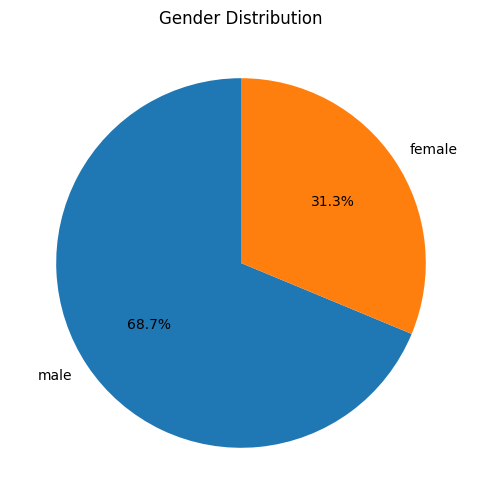

In [ ]:
import matplotlib.pyplot as plt

gender = df["Sex"].value_counts()

plt.figure(figsize=(6,6))
plt.pie(gender, labels=gender.index, autopct='%1.1f%%', startangle=90)
plt.title("Gender Distribution")
plt.show()

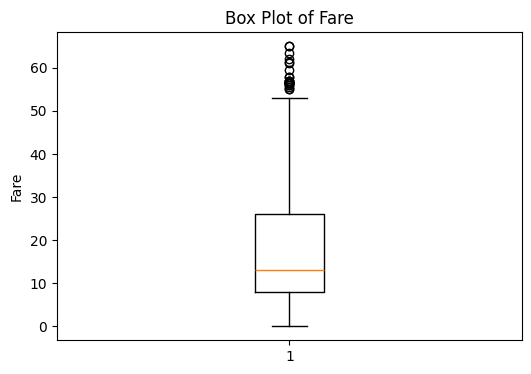

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
plt.boxplot(df["Fare"])
plt.title("Box Plot of Fare")
plt.ylabel("Fare")
plt.show()

**Conclusion**

The experiment was successfully performed using Python and Pandas in Google Colab. Missing values, duplicate records, inconsistent data formats, invalid entries, and outliers were identified and corrected. The cleaned dataset was then visualized using a pie chart and a box plot, making it suitable for further data analysis and visualization.